# Obesity Level Estimation — Machine Learning Algorithms from Scratch

**Author:** Giorgio Tuccinardi

<a href="https://colab.research.google.com/github/GiorgioTuk/obesity-ml-from-scratch/blob/main/obesity_ml_from_scratch.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Goal

Understand how core machine-learning algorithms work by **implementing them from first principles with NumPy**, and evaluate
them with a sound methodology: no target leakage, a train / validation / test split, hyperparameter tuning on validation data,
and a check of every implementation against scikit-learn.

The algorithms are applied to the *Estimation of Obesity Levels Based on Eating Habits and Physical Condition* dataset (UCI):

| Task | Target | Algorithms implemented from scratch |
|---|---|---|
| Regression | `Weight` (kg) | Linear Regression (closed form / ridge), Linear Regression (gradient descent), Feed-forward Neural Network |
| Binary classification | obese vs. not obese (`NObeyesdad` binarised) | Logistic Regression, K-Nearest Neighbors, Decision Tree |

scikit-learn is used **only** for evaluation metrics and to double-check each from-scratch model against its library
counterpart. It never fits the models that are evaluated.

## Methodology

1. Remove duplicate records and encode the categorical attributes.
2. Shuffle once with a fixed seed and split into **train (70%) / validation (15%) / test (15%)**.
3. Fit every pre-processing step (standardisation) **on the training set only**.
4. Choose hyperparameters on the **validation** set. Use the **test** set once per model, at the end.
5. **Avoid target leakage**: remove the features that encode the target (Section 2).

## Contents

0. Setup
1. The dataset
2. Target leakage
3. Pre-processing
4. Regression: linear regression (closed form, gradient descent), neural network
5. Classification: logistic regression, KNN, decision tree
6. How much leakage inflates the results
7. Final comparison
8. Critical analysis

*Originally developed for the Foundations of AI course (B.Sc., A.Y. 2023/24), later revised and extended.*

## 0. Setup

In [1]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# scikit-learn: metrics and reference implementations only
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (9, 5)

# Local copy of the dataset; when the notebook runs elsewhere (e.g. Google Colab) it is read from the GitHub repository
DATA_PATH = Path("data") / "ObesityDataSet.csv"
DATA_URL = "https://raw.githubusercontent.com/GiorgioTuk/obesity-ml-from-scratch/main/data/ObesityDataSet.csv"
DATA_SOURCE = DATA_PATH if DATA_PATH.exists() else DATA_URL

## 1. The dataset

The data (UCI Machine Learning Repository, id 544) estimate obesity levels of people from Mexico, Peru and Colombia, aged 14–61.
It contains 2111 records and 17 attributes, collected through an anonymous web survey; according to the dataset authors,
77% of the records were generated synthetically with SMOTE.

| Attribute | Meaning |
|---|---|
| `Gender`, `Age`, `Height` (m), `Weight` (kg) | Personal data |
| `family_history_with_overweight` | A family member is/was overweight |
| `FAVC` | Frequent consumption of high-calorie food |
| `FCVC` | Frequency of vegetable consumption (1–3) |
| `NCP` | Number of main meals per day (1–4) |
| `CAEC` | Eating between meals (no / Sometimes / Frequently / Always) |
| `SMOKE` | Smoker |
| `CH2O` | Daily water intake (1–3) |
| `SCC` | Monitors calorie intake |
| `FAF` | Physical activity frequency (0–3) |
| `TUE` | Time using technology devices (0–2) |
| `CALC` | Alcohol consumption (no / Sometimes / Frequently / Always) |
| `MTRANS` | Main means of transportation |
| `NObeyesdad` | Obesity level (7 classes, target) |

In [2]:
df = pd.read_csv(DATA_SOURCE)
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicated rows:", int(df.duplicated().sum()))
df.head()

Shape: (2111, 17)
Missing values: 0
Duplicated rows: 24


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


The dataset has no missing values but contains a few exact duplicates, which are removed so that the same record cannot end up both in the training and in the test set.

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)
df.describe()

Shape after removing duplicates: (2087, 17)


,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000
mean,24.353090,1.702674,86.858730,2.421466,2.701179,2.004749,1.012812,0.663035
std,6.368801,0.093186,26.190847,0.534737,0.764614,0.608284,0.853475,0.608153
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.915937,1.630178,66.000000,2.000000,2.697467,1.590922,0.124505,0.000000
50%,22.847618,1.701584,83.101100,2.396265,3.000000,2.000000,1.000000,0.630866
75%,26.000000,1.769491,108.015907,3.000000,3.000000,2.466193,1.678102,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


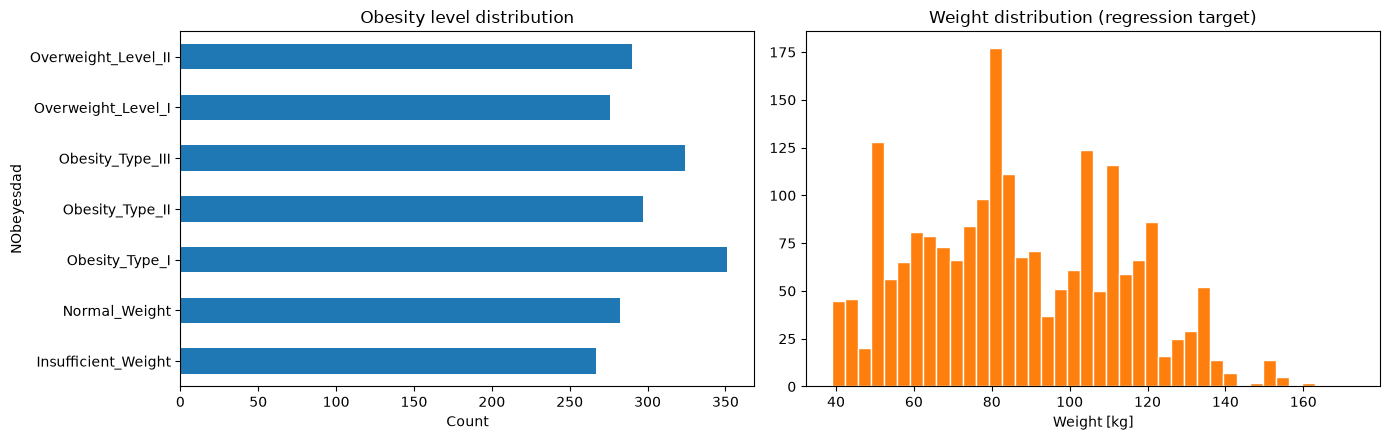

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df["NObeyesdad"].value_counts().sort_index().plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Obesity level distribution")
axes[0].set_xlabel("Count")
axes[1].hist(df["Weight"], bins=40, color="tab:orange", edgecolor="white")
axes[1].set_title("Weight distribution (regression target)")
axes[1].set_xlabel("Weight [kg]")
plt.tight_layout()
plt.show()

## 2. Target leakage: why `Height` + `Weight` cannot be used to predict `NObeyesdad`

The obesity level in this dataset was **assigned from the Body Mass Index**, $\text{BMI} = \text{Weight} / \text{Height}^2$
(WHO thresholds: < 18.5 underweight, 18.5–24.9 normal, 25–29.9 overweight, ≥ 30 obese).
If a classifier receives both `Height` and `Weight`, it does not need to learn anything about eating habits or physical
condition: it only needs to approximate a threshold on the BMI. The table below shows that the BMI ranges of the classes do
not overlap.

In [5]:
bmi = df["Weight"] / df["Height"] ** 2
(df.assign(BMI=bmi)
   .groupby("NObeyesdad")["BMI"].agg(["min", "max", "count"])
   .sort_values("min")
   .round(2))

,min,max,count
NObeyesdad,,,
Insufficient_Weight,13.00,19.08,267
Normal_Weight,18.49,24.91,282
Overweight_Level_I,22.83,28.77,276
Overweight_Level_II,25.71,30.36,290
Obesity_Type_I,29.91,35.17,351
Obesity_Type_II,34.05,39.79,297
Obesity_Type_III,36.77,50.81,324


In [6]:
OBESE_CLASSES = {"Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"}
y_binary = df["NObeyesdad"].isin(OBESE_CLASSES).astype(int).to_numpy()

bmi_rule = (bmi >= 30).astype(int).to_numpy()
print(f"Accuracy of the rule 'BMI >= 30' (no learning at all): {np.mean(bmi_rule == y_binary):.4f}")

Accuracy of the rule 'BMI >= 30' (no learning at all): 0.9971


A single hand-written rule on the BMI reproduces the binary label almost perfectly. Therefore:

- **Classification** (target `NObeyesdad`): `Weight` is removed from the inputs. `Height` alone is kept, since on its own it
  does not determine the label.
- **Regression** (target `Weight`): `NObeyesdad` is removed from the inputs, because together with `Height` it reveals the BMI
  range and hence the weight.

The task becomes the meaningful one: *estimating obesity / weight from lifestyle and personal attributes*. Section 6 quantifies
how much the leaking feature would inflate the results.

## 3. Pre-processing

### 3.1 Encoding
- **Binary** `yes`/`no` attributes and `Gender` → 0/1.
- **Ordinal** attributes `CAEC` and `CALC` (no < Sometimes < Frequently < Always) → 0, 1, 2, 3, preserving their order
  (one-hot encoding would discard it and add useless columns).
- **Nominal** attribute `MTRANS` → one-hot encoding.
- **Classification target**: classes up to and including *Overweight_Level_II* → `0`; *Obesity_Type_I/II/III* → `1`.

In [7]:
BINARY_COLUMNS = ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]
ORDINAL_COLUMNS = ["CAEC", "CALC"]
ORDINAL_MAP = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}


def encode_features(data: pd.DataFrame) -> pd.DataFrame:
    # Returns a fully numeric copy of the input attributes (targets excluded)
    X = data.drop(columns=["NObeyesdad"]).copy()
    X["Gender"] = (X["Gender"] == "Male").astype(int)
    for col in BINARY_COLUMNS:
        X[col] = X[col].map({"no": 0, "yes": 1})
    for col in ORDINAL_COLUMNS:
        X[col] = X[col].map(ORDINAL_MAP)
    X = pd.get_dummies(X, columns=["MTRANS"], prefix="MTRANS", dtype=int)
    assert not X.isna().any().any(), "unexpected category during encoding"
    return X


features = encode_features(df)

# Regression: predict Weight, without NObeyesdad (already excluded by encode_features)
X_reg_df = features.drop(columns=["Weight"])
y_reg = df["Weight"].to_numpy(dtype=float)

# Classification: predict obese / not obese, without Weight (leakage, see Section 2)
X_cls_df = features.drop(columns=["Weight"])
y_cls = y_binary

print("Regression features:    ", list(X_reg_df.columns))
print("Classification features:", list(X_cls_df.columns))
print(f"Positive (obese) rate: {y_cls.mean():.3f}")

Regression features:     ['Gender', 'Age', 'Height', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS_Automobile', 'MTRANS_Bike', 'MTRANS_Motorbike', 'MTRANS_Public_Transportation', 'MTRANS_Walking']
Classification features: ['Gender', 'Age', 'Height', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS_Automobile', 'MTRANS_Bike', 'MTRANS_Motorbike', 'MTRANS_Public_Transportation', 'MTRANS_Walking']
Positive (obese) rate: 0.466


### 3.2 Train / validation / test split

The data are shuffled once with a fixed seed (reproducible results) and split into 70% training, 15% validation and 15% test.
The same split is used for every model so that all results are directly comparable.

- **Training set** → fit the model parameters.
- **Validation set** → choose the hyperparameters.
- **Test set** → final, unbiased estimate of the performance. It is never used to take decisions.

In [8]:
def train_val_test_split_indices(n, val_size=0.15, test_size=0.15, seed=RANDOM_STATE):
    idx = np.random.default_rng(seed).permutation(n)
    n_test, n_val = int(n * test_size), int(n * val_size)
    return idx[n_test + n_val:], idx[n_test:n_test + n_val], idx[:n_test]


train_idx, val_idx, test_idx = train_val_test_split_indices(len(df))
print(f"train: {len(train_idx)}  validation: {len(val_idx)}  test: {len(test_idx)}")
for name, idx in [("train", train_idx), ("validation", val_idx), ("test", test_idx)]:
    print(f"  obese rate in {name:<10}: {y_cls[idx].mean():.3f}")

train: 1461  validation: 313  test: 313
  obese rate in train     : 0.464
  obese rate in validation: 0.466
  obese rate in test      : 0.473


### 3.3 Standardisation

Gradient-based and distance-based algorithms need features on comparable scales:

$$x_{\text{std}} = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

Mean and standard deviation are computed **on the training set only** and then applied unchanged to validation and test data,
exactly as would happen with new, unseen samples.

In [9]:
class StandardScalerScratch:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0  # constant columns: avoid division by zero
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_


def add_bias(X):
    return np.hstack([np.ones((X.shape[0], 1)), X])


def split_and_scale(X_df, y):
    X = X_df.to_numpy(dtype=float)
    scaler = StandardScalerScratch().fit(X[train_idx])
    return (scaler.transform(X[train_idx]), scaler.transform(X[val_idx]), scaler.transform(X[test_idx]),
            y[train_idx], y[val_idx], y[test_idx])


Xr_train, Xr_val, Xr_test, yr_train, yr_val, yr_test = split_and_scale(X_reg_df, y_reg)
Xc_train, Xc_val, Xc_test, yc_train, yc_val, yc_test = split_and_scale(X_cls_df, y_cls)

### 3.4 Evaluation metrics

**Regression**

$$\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2 \qquad
\text{RMSE} = \sqrt{\text{MSE}} \qquad
\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i| \qquad
R^2 = 1-\frac{\sum_i (y_i-\hat y_i)^2}{\sum_i (y_i-\bar y)^2}$$

**Classification**: accuracy, precision, recall, F1-score and confusion matrix (obese = positive class).
The metric functions below are implemented from scratch; scikit-learn's versions are used only as a cross-check.

In [10]:
def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))


def rmse(y_true, y_pred):
    return float(np.sqrt(mse(y_true, y_pred)))


def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))


def r2(y_true, y_pred):
    return float(1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2))


def regression_report(y_true, y_pred):
    return {"MSE": mse(y_true, y_pred), "RMSE": rmse(y_true, y_pred), "MAE": mae(y_true, y_pred), "R2": r2(y_true, y_pred)}


def classification_report(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred), "F1": f1_score(y_true, y_pred)}


# Sanity check against scikit-learn
_a, _b = np.array([1.0, 2.0, 4.0]), np.array([1.5, 2.0, 3.0])
assert np.isclose(mse(_a, _b), mean_squared_error(_a, _b))
assert np.isclose(mae(_a, _b), mean_absolute_error(_a, _b))
assert np.isclose(r2(_a, _b), r2_score(_a, _b))

regression_results = {}      # test-set results, filled in by each section
classification_results = {}

## 4. Regression — predicting `Weight`

### 4.0 Baseline
A model is only useful if it beats the trivial predictor that always outputs the mean training weight.

In [11]:
baseline_pred = np.full_like(yr_test, yr_train.mean())
regression_results["Baseline (mean)"] = regression_report(yr_test, baseline_pred)
pd.DataFrame(regression_results).T.round(3)

,MSE,RMSE,MAE,R2
Baseline (mean),628.768,25.075,20.698,-0.001


### 4.1 Linear Regression — closed form (with optional ridge penalty)

With the design matrix $\mathbf X$ (bias column included) the least-squares solution is given by the normal equations, computed
through the Moore–Penrose pseudo-inverse:

$$\mathbf w = (\mathbf X^T \mathbf X)^{-1} \mathbf X^T \mathbf y = \mathbf X^{+}\mathbf y$$

Plain least squares has no hyperparameter. To have something meaningful to tune, an **L2 (ridge) penalty** $\lambda$ is added:

$$\mathbf w = (\mathbf X^T \mathbf X + \lambda \mathbf I')^{-1} \mathbf X^T \mathbf y$$

where $\mathbf I'$ is the identity matrix with a 0 in the bias position (the intercept is not penalised).
$\lambda = 0$ gives back ordinary least squares.

In [12]:
class LinearRegressionClosedForm:
    def __init__(self, l2=0.0):
        self.l2 = l2

    def fit(self, X, y):
        Xb = add_bias(X)
        if self.l2 == 0:
            self.w_ = np.linalg.pinv(Xb) @ y
        else:
            penalty = self.l2 * np.eye(Xb.shape[1])
            penalty[0, 0] = 0.0  # do not penalise the bias
            self.w_ = np.linalg.solve(Xb.T @ Xb + penalty, Xb.T @ y)
        return self

    def predict(self, X):
        return add_bias(X) @ self.w_

**Hyperparameter tuning**: $\lambda$ is searched on a logarithmic grid; the value with the lowest *validation* MSE is selected. The grid can be refined around the best value or extended with more points.

lambda =     0.0: validation MSE = 335.401
lambda =    0.01: validation MSE = 335.401
lambda =     0.1: validation MSE = 335.402
lambda =       1: validation MSE = 335.412
lambda =       3: validation MSE = 335.437
lambda =      10: validation MSE = 335.540
lambda =      30: validation MSE = 335.962
lambda =     100: validation MSE = 338.533
lambda =     300: validation MSE = 350.330
lambda =    1000: validation MSE = 399.432

Best lambda: 0.0


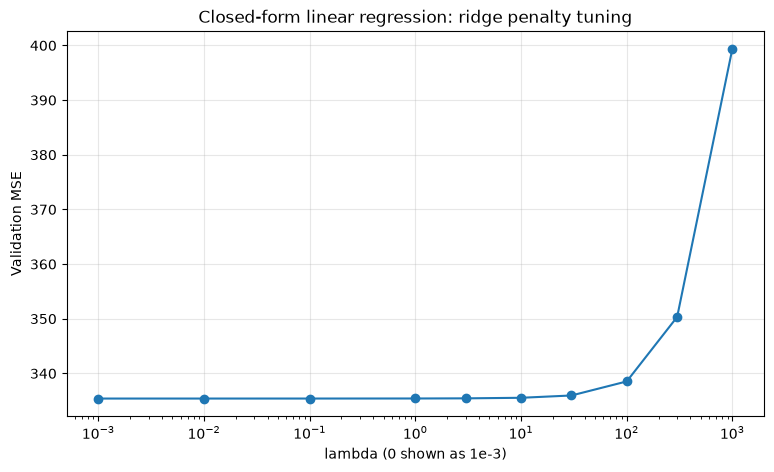

In [13]:
lambda_grid = [0.0, 0.01, 0.1, 1, 3, 10, 30, 100, 300, 1000]
val_mse_closed = []
for lam in lambda_grid:
    model = LinearRegressionClosedForm(l2=lam).fit(Xr_train, yr_train)
    val_mse_closed.append(mse(yr_val, model.predict(Xr_val)))
    print(f"lambda = {lam:>7}: validation MSE = {val_mse_closed[-1]:.3f}")

best_lambda = lambda_grid[int(np.argmin(val_mse_closed))]
print(f"\nBest lambda: {best_lambda}")

plt.semilogx([l if l > 0 else 1e-3 for l in lambda_grid], val_mse_closed, "o-")
plt.xlabel("lambda (0 shown as 1e-3)")
plt.ylabel("Validation MSE")
plt.title("Closed-form linear regression: ridge penalty tuning")
plt.grid(alpha=0.3)
plt.show()

In [14]:
lr_closed = LinearRegressionClosedForm(l2=best_lambda).fit(Xr_train, yr_train)
regression_results["Linear Reg. (closed form)"] = regression_report(yr_test, lr_closed.predict(Xr_test))

# Cross-check with scikit-learn (same lambda; alpha=0 is ordinary least squares)
from sklearn.linear_model import LinearRegression, Ridge
sk_lin = (Ridge(alpha=best_lambda) if best_lambda > 0 else LinearRegression()).fit(Xr_train, yr_train)
print("Max |difference| between scratch and sklearn predictions:",
      np.abs(sk_lin.predict(Xr_test) - lr_closed.predict(Xr_test)).max())
regression_results["Linear Reg. (sklearn check)"] = regression_report(yr_test, sk_lin.predict(Xr_test))
pd.DataFrame(regression_results).T.round(3)

Max |difference| between scratch and sklearn predictions: 5.400124791776761e-13


,MSE,RMSE,MAE,R2
Baseline (mean),628.768,25.075,20.698,-0.001
Linear Reg. (closed form),322.879,17.969,13.970,0.486
Linear Reg. (sklearn check),322.879,17.969,13.970,0.486


### 4.2 Linear Regression — batch gradient descent

Cost function (MSE, halved to simplify the derivative) and its gradient:

$$J(\boldsymbol\theta) = \frac{1}{2m}\lVert \mathbf X\boldsymbol\theta - \mathbf y\rVert^2 \qquad
\nabla J = \frac{1}{m}\mathbf X^T(\mathbf X\boldsymbol\theta - \mathbf y) \qquad
\boldsymbol\theta \leftarrow \boldsymbol\theta - \eta\,\nabla J$$

Standardised features are essential here: with very different scales the cost surface is elongated and gradient descent
converges very slowly.

In [15]:
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000, seed=RANDOM_STATE):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.seed = seed

    @staticmethod
    def cost(Xb, y, theta):
        return float(np.mean((Xb @ theta - y) ** 2) / 2)

    def fit(self, X, y):
        Xb = add_bias(X)
        m = len(y)
        self.theta_ = np.random.default_rng(self.seed).normal(scale=0.01, size=Xb.shape[1])
        self.cost_history_ = []
        for _ in range(self.n_iterations):
            gradient = Xb.T @ (Xb @ self.theta_ - y) / m
            self.theta_ -= self.learning_rate * gradient
            self.cost_history_.append(self.cost(Xb, y, self.theta_))
        return self

    def predict(self, X):
        return add_bias(X) @ self.theta_

**Hyperparameter tuning**: grid search over the learning rate $\eta$ and the number of iterations. Each combination is trained
on the training set and scored by its **validation MSE** (the original version compared the final *training* cost, which
cannot detect overfitting and does not reflect generalisation).

In [16]:
gd_learning_rates = [0.001, 0.01, 0.1, 0.3]
gd_iterations = [100, 1000, 5000]

gd_search = []
for eta, n_iter in product(gd_learning_rates, gd_iterations):
    model = LinearRegressionGD(learning_rate=eta, n_iterations=n_iter).fit(Xr_train, yr_train)
    gd_search.append({"learning_rate": eta, "iterations": n_iter,
                      "train_cost": model.cost_history_[-1], "val_MSE": mse(yr_val, model.predict(Xr_val))})

gd_search = pd.DataFrame(gd_search)
best_gd = gd_search.loc[gd_search["val_MSE"].idxmin()]
print(gd_search.round(3).to_string(index=False))
print(f"\nBest: learning_rate={best_gd.learning_rate}, iterations={int(best_gd.iterations)}")

 learning_rate  iterations  train_cost  val_MSE
         0.001         100    3382.898 6894.725
         0.001        1000     677.071 1490.269
         0.001        5000     148.769  339.429
         0.010         100     672.305 1480.520
         0.010        1000     147.845  335.593
         0.010        5000     147.799  335.401
         0.100         100     147.842  335.582
         0.100        1000     147.799  335.401
         0.100        5000     147.799  335.401
         0.300         100     147.799  335.401
         0.300        1000     147.799  335.401
         0.300        5000     147.799  335.401

Best: learning_rate=0.3, iterations=1000


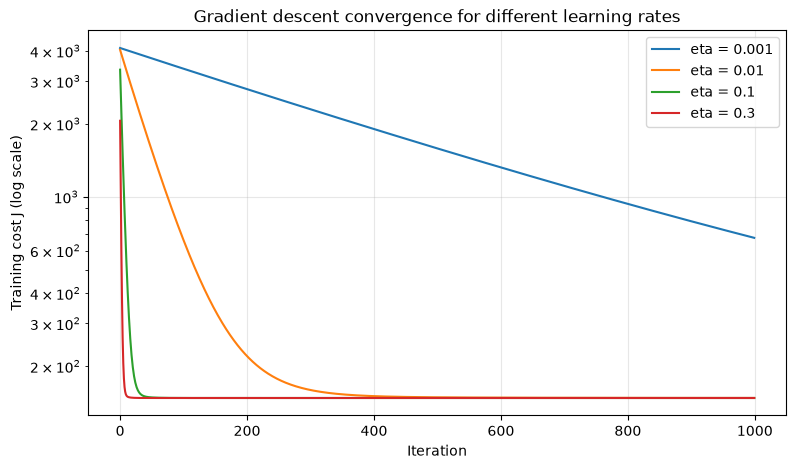

In [17]:
fig, ax = plt.subplots()
for eta in gd_learning_rates:
    hist = LinearRegressionGD(learning_rate=eta, n_iterations=1000).fit(Xr_train, yr_train).cost_history_
    ax.plot(hist, label=f"eta = {eta}")
ax.set_yscale("log")
ax.set_xlabel("Iteration")
ax.set_ylabel("Training cost J (log scale)")
ax.set_title("Gradient descent convergence for different learning rates")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [18]:
lr_gd = LinearRegressionGD(learning_rate=best_gd.learning_rate, n_iterations=int(best_gd.iterations)).fit(Xr_train, yr_train)
regression_results["Linear Reg. (gradient descent)"] = regression_report(yr_test, lr_gd.predict(Xr_test))
print("Max |theta_GD - w_closed_form(lambda=0)|:",
      np.abs(lr_gd.theta_ - LinearRegressionClosedForm(0).fit(Xr_train, yr_train).w_).max())
pd.DataFrame(regression_results).T.round(3)

Max |theta_GD - w_closed_form(lambda=0)|: 0.0003894068389329597


,MSE,RMSE,MAE,R2
Baseline (mean),628.768,25.075,20.698,-0.001
Linear Reg. (closed form),322.879,17.969,13.970,0.486
Linear Reg. (sklearn check),322.879,17.969,13.970,0.486
Linear Reg. (gradient descent),322.879,17.969,13.970,0.486


With a suitable learning rate and enough iterations, gradient descent converges to the same solution as the closed form (the
cost is convex, so there is a single global minimum). Too small a learning rate stops far from the minimum within the
iteration budget; on standardised data even fairly large rates are stable.

### 4.3 Feed-forward Neural Network (MLP) — extra

A fully connected network trained with mini-batch gradient descent and back-propagation:

- hidden layers with **ReLU** activation, $\text{ReLU}(z) = \max(0, z)$;
- **linear output layer** (regression output must be able to take any real value — the original version applied ReLU to the
  output too);
- **He initialisation** of the weights, $W \sim \mathcal N(0, 2/n_\text{in})$, suited to ReLU;
- loss: MSE with L2 weight decay $\lambda$;
- the target is standardised during training and converted back to kilograms for prediction.

In [19]:
class NeuralNetworkRegressor:
    def __init__(self, hidden_layers=(64,), learning_rate=0.01, epochs=200, l2=0.0, batch_size=64, seed=RANDOM_STATE):
        self.hidden_layers = tuple(hidden_layers)
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2
        self.batch_size = batch_size
        self.seed = seed

    def _init_params(self, n_inputs):
        sizes = [n_inputs, *self.hidden_layers, 1]
        self.W_ = [self.rng_.normal(0, np.sqrt(2 / n_in), size=(n_in, n_out)) for n_in, n_out in zip(sizes[:-1], sizes[1:])]
        self.b_ = [np.zeros((1, n_out)) for n_out in sizes[1:]]

    def _forward(self, X):
        activations, pre_activations = [X], []
        for i, (W, b) in enumerate(zip(self.W_, self.b_)):
            z = activations[-1] @ W + b
            pre_activations.append(z)
            is_output = i == len(self.W_) - 1
            activations.append(z if is_output else np.maximum(0, z))
        return pre_activations, activations

    def _backward(self, pre_activations, activations, y):
        m = y.shape[0]
        delta = (activations[-1] - y) / m           # dLoss/dz of the linear output layer
        grads_W, grads_b = [], []
        for i in reversed(range(len(self.W_))):
            grads_W.insert(0, activations[i].T @ delta + self.l2 * self.W_[i])
            grads_b.insert(0, delta.sum(axis=0, keepdims=True))
            if i > 0:
                delta = (delta @ self.W_[i].T) * (pre_activations[i - 1] > 0)
        return grads_W, grads_b

    def fit(self, X, y):
        self.rng_ = np.random.default_rng(self.seed)
        self._init_params(X.shape[1])
        self.y_mean_, self.y_std_ = y.mean(), y.std()
        y_std = ((y - self.y_mean_) / self.y_std_).reshape(-1, 1)
        self.loss_history_ = []
        for _ in range(self.epochs):
            order = self.rng_.permutation(len(X))
            for start in range(0, len(X), self.batch_size):
                batch = order[start:start + self.batch_size]
                pre, act = self._forward(X[batch])
                grads_W, grads_b = self._backward(pre, act, y_std[batch])
                for i in range(len(self.W_)):
                    self.W_[i] -= self.learning_rate * grads_W[i]
                    self.b_[i] -= self.learning_rate * grads_b[i]
            self.loss_history_.append(float(np.mean((self._forward(X)[1][-1] - y_std) ** 2)))
        return self

    def predict(self, X):
        return self._forward(X)[1][-1].ravel() * self.y_std_ + self.y_mean_

**Gradient check.** Before trusting back-propagation, the analytical gradient is compared with a numerical
(finite-difference) estimate on a tiny network.

In [20]:
def numerical_gradient_check(eps=1e-6):
    rng = np.random.default_rng(0)
    X, y = rng.normal(size=(8, 5)), rng.normal(size=(8, 1))
    net = NeuralNetworkRegressor(hidden_layers=(4, 3), l2=0.01)
    net.rng_ = rng
    net._init_params(5)

    def loss():
        out = net._forward(X)[1][-1]
        return np.mean((out - y) ** 2) / 2 + net.l2 / 2 * sum(np.sum(W ** 2) for W in net.W_)

    pre, act = net._forward(X)
    grads_W, _ = net._backward(pre, act, y)
    max_rel_err = 0.0
    for W, gW in zip(net.W_, grads_W):
        for idx in np.ndindex(W.shape):
            old = W[idx]
            W[idx] = old + eps; lp = loss()
            W[idx] = old - eps; lm = loss()
            W[idx] = old
            num = (lp - lm) / (2 * eps)
            max_rel_err = max(max_rel_err, abs(num - gW[idx]) / max(1e-8, abs(num) + abs(gW[idx])))
    return max_rel_err


print(f"Max relative error between analytical and numerical gradients: {numerical_gradient_check():.2e}")

Max relative error between analytical and numerical gradients: 3.24e-08


**Hyperparameter tuning**: grid search over architecture, learning rate, number of epochs and L2 strength, scored by validation
MSE. With 4 hyperparameters the grid grows multiplicatively, so it is kept small; random search or Bayesian optimisation would
be the natural next step to explore a larger space.

In [21]:
nn_grid = {
    "hidden_layers": [(32,), (64,), (64, 32)],
    "learning_rate": [0.005, 0.02],
    "epochs": [50, 150],
    "l2": [0.0, 1e-3],
}

nn_search = []
for hidden, eta, epochs, l2 in product(*nn_grid.values()):
    net = NeuralNetworkRegressor(hidden_layers=hidden, learning_rate=eta, epochs=epochs, l2=l2).fit(Xr_train, yr_train)
    nn_search.append({"hidden_layers": hidden, "learning_rate": eta, "epochs": epochs, "l2": l2,
                      "val_MSE": mse(yr_val, net.predict(Xr_val))})

nn_search = pd.DataFrame(nn_search).sort_values("val_MSE")
best_nn = nn_search.iloc[0]
print(nn_search.round(3).to_string(index=False))

hidden_layers  learning_rate  epochs    l2  val_MSE
     (64, 32)          0.020     150 0.001  103.735
     (64, 32)          0.020     150 0.000  105.630
     (64, 32)          0.020      50 0.001  122.904
     (64, 32)          0.020      50 0.000  123.338
     (64, 32)          0.005     150 0.001  131.117
     (64, 32)          0.005     150 0.000  131.326
        (32,)          0.020     150 0.001  155.219
        (32,)          0.020     150 0.000  157.554
        (64,)          0.020     150 0.001  182.723
        (64,)          0.020      50 0.001  187.147
        (64,)          0.020     150 0.000  187.576
        (64,)          0.020      50 0.000  188.527
        (32,)          0.020      50 0.001  188.993
        (32,)          0.020      50 0.000  190.165
        (64,)          0.005     150 0.001  194.035
        (64,)          0.005     150 0.000  194.912
        (32,)          0.005     150 0.001  195.486
        (32,)          0.005     150 0.000  196.202
     (64, 32

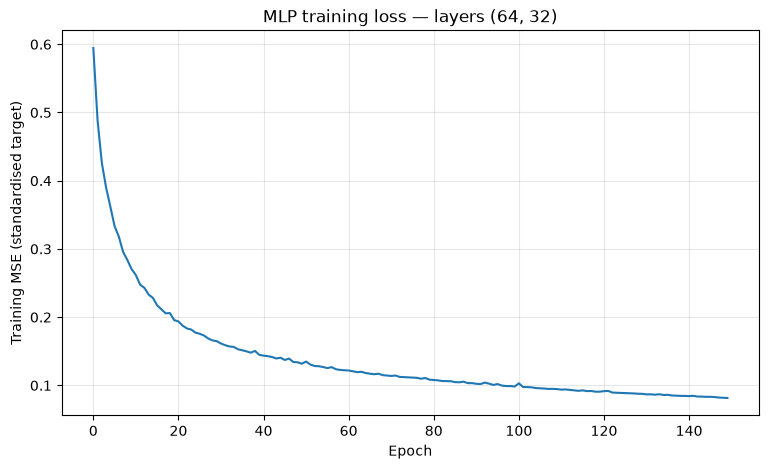

,MSE,RMSE,MAE,R2
Baseline (mean),628.768,25.075,20.698,-0.001
Linear Reg. (closed form),322.879,17.969,13.970,0.486
Linear Reg. (sklearn check),322.879,17.969,13.970,0.486
Linear Reg. (gradient descent),322.879,17.969,13.970,0.486
Neural Network,146.710,12.112,7.359,0.767
Neural Network (sklearn check),138.297,11.760,6.639,0.780


In [22]:
nn = NeuralNetworkRegressor(hidden_layers=best_nn.hidden_layers, learning_rate=best_nn.learning_rate,
                            epochs=int(best_nn.epochs), l2=best_nn.l2).fit(Xr_train, yr_train)
regression_results["Neural Network"] = regression_report(yr_test, nn.predict(Xr_test))

plt.plot(nn.loss_history_)
plt.xlabel("Epoch")
plt.ylabel("Training MSE (standardised target)")
plt.title(f"MLP training loss — layers {best_nn.hidden_layers}")
plt.grid(alpha=0.3)
plt.show()

# Cross-check with scikit-learn's MLP using the same architecture
from sklearn.neural_network import MLPRegressor
sk_mlp = MLPRegressor(hidden_layer_sizes=best_nn.hidden_layers, max_iter=2000, random_state=RANDOM_STATE)
sk_mlp.fit(Xr_train, (yr_train - yr_train.mean()) / yr_train.std())
regression_results["Neural Network (sklearn check)"] = regression_report(
    yr_test, sk_mlp.predict(Xr_test) * yr_train.std() + yr_train.mean())
pd.DataFrame(regression_results).T.round(3)

## 5. Classification — obese vs. not obese

### 5.0 Baseline
The classes are fairly balanced, so the majority-class predictor gives the reference accuracy to beat.

In [23]:
majority = int(yc_train.mean() >= 0.5)
print(f"Majority class in training: {majority}")
print(f"Majority-class accuracy on test: {np.mean(yc_test == majority):.4f}")

Majority class in training: 0
Majority-class accuracy on test: 0.5272


### 5.1 Logistic Regression

The model outputs the probability of the positive class through the sigmoid function:

$$h_{\boldsymbol\theta}(\mathbf x) = \sigma(\boldsymbol\theta^T\mathbf x) = \frac{1}{1+e^{-\boldsymbol\theta^T\mathbf x}}$$

and is trained by gradient descent on the (L2-regularised) cross-entropy loss:

$$J(\boldsymbol\theta) = -\frac{1}{m}\sum_{i=1}^m\left[y_i\log h_i + (1-y_i)\log(1-h_i)\right] + \frac{\lambda}{2m}\lVert\boldsymbol\theta_{1:}\rVert^2
\qquad
\nabla J = \frac{1}{m}\mathbf X^T(\mathbf h-\mathbf y) + \frac{\lambda}{m}\boldsymbol\theta_{1:}$$

The sigmoid is computed with clipping and the logarithms with a small $\epsilon$ to avoid numerical overflow and $\log 0$.

In [24]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


class LogisticRegressionGD:
    def __init__(self, learning_rate=0.1, n_iterations=1000, l2=0.0, threshold=0.5):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.l2 = l2
        self.threshold = threshold

    def _cost(self, Xb, y):
        h = sigmoid(Xb @ self.theta_)
        eps = 1e-12
        cross_entropy = -np.mean(y * np.log(h + eps) + (1 - y) * np.log(1 - h + eps))
        return float(cross_entropy + self.l2 / (2 * len(y)) * np.sum(self.theta_[1:] ** 2))

    def fit(self, X, y):
        Xb = add_bias(X)
        m = len(y)
        self.theta_ = np.zeros(Xb.shape[1])
        self.cost_history_ = []
        for _ in range(self.n_iterations):
            gradient = Xb.T @ (sigmoid(Xb @ self.theta_) - y) / m
            gradient[1:] += self.l2 / m * self.theta_[1:]
            self.theta_ -= self.learning_rate * gradient
            self.cost_history_.append(self._cost(Xb, y))
        return self

    def predict_proba(self, X):
        return sigmoid(add_bias(X) @ self.theta_)

    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).astype(int)

**Hyperparameter tuning**: grid search on learning rate, number of iterations and L2 strength, scored by validation accuracy
(ties broken by validation cross-entropy). The model that is returned is retrained with the best combination — the original
version returned the weights of the *last* combination tried instead of the best one.

In [25]:
log_grid = {"learning_rate": [0.01, 0.1, 0.5], "n_iterations": [500, 2000, 5000], "l2": [0.0, 1.0, 10.0]}

log_search = []
for eta, n_iter, l2 in product(*log_grid.values()):
    model = LogisticRegressionGD(learning_rate=eta, n_iterations=n_iter, l2=l2).fit(Xc_train, yc_train)
    p_val = model.predict_proba(Xc_val)
    log_search.append({"learning_rate": eta, "n_iterations": n_iter, "l2": l2,
                       "val_accuracy": np.mean((p_val >= 0.5) == yc_val),
                       "val_log_loss": -np.mean(yc_val * np.log(p_val + 1e-12) + (1 - yc_val) * np.log(1 - p_val + 1e-12))})

log_search = pd.DataFrame(log_search).sort_values(["val_accuracy", "val_log_loss"], ascending=[False, True])
best_log = log_search.iloc[0]
print(log_search.round(4).head(10).to_string(index=False))

 learning_rate  n_iterations   l2  val_accuracy  val_log_loss
          0.10           500  0.0        0.8307        0.4176
          0.01          5000  0.0        0.8307        0.4177
          0.10           500  1.0        0.8307        0.4179
          0.01          5000  1.0        0.8307        0.4179
          0.10          2000 10.0        0.8307        0.4196
          0.50           500 10.0        0.8307        0.4196
          0.10          5000 10.0        0.8307        0.4196
          0.50          2000 10.0        0.8307        0.4196
          0.50          5000 10.0        0.8307        0.4196
          0.10           500 10.0        0.8307        0.4206


Prediction agreement scratch vs sklearn: 0.9968051118210862


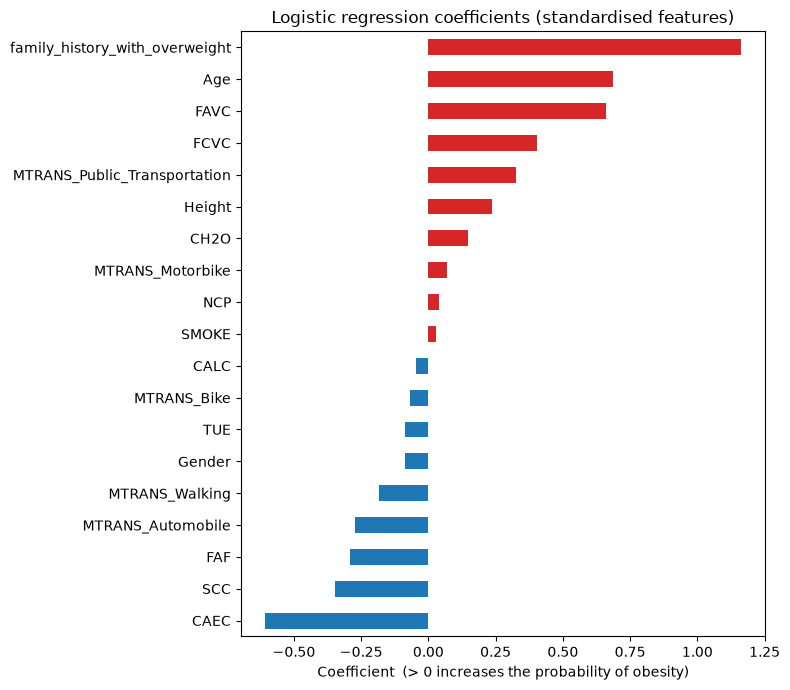

,Accuracy,Precision,Recall,F1
Logistic Regression,0.7444,0.6868,0.8446,0.7576
Logistic Regression (sklearn check),0.7412,0.6851,0.8378,0.7538


In [26]:
log_reg = LogisticRegressionGD(learning_rate=best_log.learning_rate, n_iterations=int(best_log.n_iterations),
                               l2=best_log.l2).fit(Xc_train, yc_train)
classification_results["Logistic Regression"] = classification_report(yc_test, log_reg.predict(Xc_test))

# Cross-check: sklearn's C is the inverse of the regularisation strength (C = 1/lambda)
from sklearn.linear_model import LogisticRegression
sk_log = LogisticRegression(C=1 / best_log.l2 if best_log.l2 > 0 else 1e10, max_iter=5000).fit(Xc_train, yc_train)
classification_results["Logistic Regression (sklearn check)"] = classification_report(yc_test, sk_log.predict(Xc_test))
print("Prediction agreement scratch vs sklearn:", np.mean(log_reg.predict(Xc_test) == sk_log.predict(Xc_test)))

coefs = pd.Series(log_reg.theta_[1:], index=X_cls_df.columns).sort_values()
coefs.plot.barh(figsize=(8, 7), color=np.where(coefs > 0, "tab:red", "tab:blue"))
plt.title("Logistic regression coefficients (standardised features)")
plt.xlabel("Coefficient  (> 0 increases the probability of obesity)")
plt.tight_layout()
plt.show()
pd.DataFrame(classification_results).T.round(4)

### 5.2 K-Nearest Neighbors

KNN has no training phase: it stores the training set and classifies a new point by majority vote among its $k$ closest
training points. Two distance metrics are compared:

$$d_\text{euclidean}(\mathbf a,\mathbf b) = \sqrt{\textstyle\sum_j (a_j-b_j)^2} \qquad d_\text{manhattan}(\mathbf a,\mathbf b) = \textstyle\sum_j |a_j-b_j|$$

Distances are computed in a vectorised way (all test points against all training points at once) instead of with Python
loops. Because KNN is based on distances, **standardised features are essential**: otherwise attributes measured on larger
scales (e.g. `Age`) dominate the distance. The original version used unscaled features.

In [27]:
class KNNClassifier:
    def __init__(self, k=5, metric="euclidean"):
        self.k = k
        self.metric = metric

    def fit(self, X, y):
        self.X_train_, self.y_train_ = X, y
        return self

    def _distances(self, X):
        if self.metric == "euclidean":
            sq = (X ** 2).sum(1)[:, None] + (self.X_train_ ** 2).sum(1)[None, :] - 2 * X @ self.X_train_.T
            return np.sqrt(np.maximum(sq, 0))
        if self.metric == "manhattan":
            return np.abs(X[:, None, :] - self.X_train_[None, :, :]).sum(axis=2)
        raise ValueError(f"unknown metric {self.metric}")

    def predict(self, X):
        nearest = np.argsort(self._distances(X), axis=1, kind="stable")[:, :self.k]
        votes = self.y_train_[nearest]                  # shape (n_samples, k), binary labels
        return (votes.mean(axis=1) > 0.5).astype(int)   # majority vote (odd k => no ties)

**Hyperparameter tuning**: odd values of $k$ from 1 to 31 (odd values avoid ties in binary voting) × the two distance metrics, scored by validation accuracy.

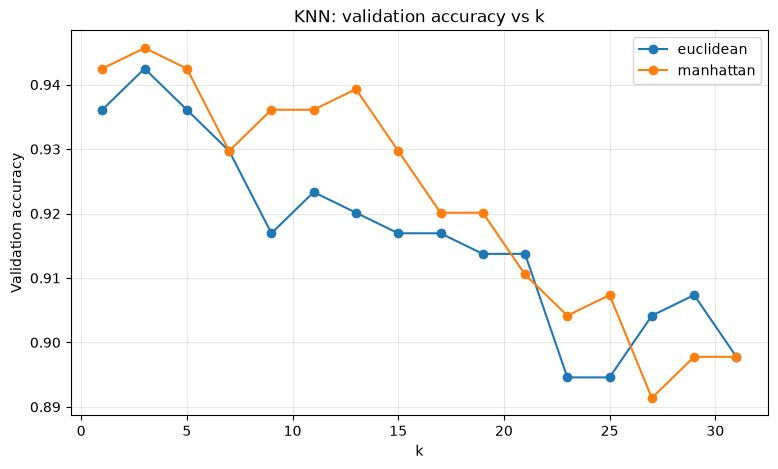

Best: k=3, metric=manhattan, validation accuracy=0.9457


In [28]:
k_values = list(range(1, 32, 2))
knn_search = {metric: [] for metric in ["euclidean", "manhattan"]}
for metric in knn_search:
    for k in k_values:
        pred = KNNClassifier(k=k, metric=metric).fit(Xc_train, yc_train).predict(Xc_val)
        knn_search[metric].append(np.mean(pred == yc_val))

for metric, accs in knn_search.items():
    plt.plot(k_values, accs, "o-", label=metric)
plt.xlabel("k")
plt.ylabel("Validation accuracy")
plt.title("KNN: validation accuracy vs k")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_knn_metric, best_knn_k, best_knn_acc = max(
    ((m, k, a) for m, accs in knn_search.items() for k, a in zip(k_values, accs)), key=lambda t: t[2])
print(f"Best: k={best_knn_k}, metric={best_knn_metric}, validation accuracy={best_knn_acc:.4f}")

In [29]:
knn = KNNClassifier(k=best_knn_k, metric=best_knn_metric).fit(Xc_train, yc_train)
classification_results["KNN"] = classification_report(yc_test, knn.predict(Xc_test))

from sklearn.neighbors import KNeighborsClassifier
sk_knn = KNeighborsClassifier(n_neighbors=best_knn_k, metric=best_knn_metric).fit(Xc_train, yc_train)
classification_results["KNN (sklearn check)"] = classification_report(yc_test, sk_knn.predict(Xc_test))
print("Prediction agreement scratch vs sklearn:", np.mean(knn.predict(Xc_test) == sk_knn.predict(Xc_test)))
pd.DataFrame(classification_results).T.round(4)

Prediction agreement scratch vs sklearn: 1.0


,Accuracy,Precision,Recall,F1
Logistic Regression,0.7444,0.6868,0.8446,0.7576
Logistic Regression (sklearn check),0.7412,0.6851,0.8378,0.7538
KNN,0.9457,0.9338,0.9527,0.9431
KNN (sklearn check),0.9457,0.9338,0.9527,0.9431


### 5.3 Decision Tree

A binary tree is grown recursively. At each node, every feature and every candidate threshold (midpoints between consecutive
distinct values) is evaluated, and the split with the largest **information gain** is chosen:

$$H(S) = -\sum_c p_c\log_2 p_c \qquad IG = H(S) - \frac{|S_L|}{|S|}H(S_L) - \frac{|S_R|}{|S|}H(S_R)$$

Growth stops when the node is pure, the maximum depth is reached, the node has fewer than `min_samples_split` samples, or no
split improves the entropy. Leaves predict the majority class.

Implementation note: for each feature the values are sorted once and the class counts on the left of every possible threshold
are obtained with a cumulative sum, so all thresholds are scored in a single vectorised pass (instead of one pass per
threshold). This makes the search fast enough to tune the hyperparameters properly.

In [30]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf(self):
        return self.value is not None


def entropy(y):
    p = np.bincount(y, minlength=2) / len(y)
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))


def binary_entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


class DecisionTreeClassifierScratch:
    def __init__(self, max_depth=None, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split

    def fit(self, X, y):
        self.n_nodes_ = 0
        self.root_ = self._grow(X, y.astype(int), depth=0)
        return self

    def _leaf(self, y):
        self.n_nodes_ += 1
        return Node(value=int(np.bincount(y, minlength=2).argmax()))

    def _grow(self, X, y, depth):
        if (len(np.unique(y)) == 1 or len(y) < self.min_samples_split
                or (self.max_depth is not None and depth >= self.max_depth)):
            return self._leaf(y)
        feature, threshold, gain = self._best_split(X, y)
        if feature is None or gain <= 0:
            return self._leaf(y)
        mask = X[:, feature] <= threshold
        self.n_nodes_ += 1
        return Node(feature, threshold,
                    self._grow(X[mask], y[mask], depth + 1),
                    self._grow(X[~mask], y[~mask], depth + 1))

    def _best_split(self, X, y):
        n = len(y)
        parent_entropy = entropy(y)
        best_feature, best_threshold, best_gain = None, None, 0.0
        n_left = np.arange(1, n)               # samples on the left for split after position i
        n_right = n - n_left
        for feature in range(X.shape[1]):
            order = np.argsort(X[:, feature], kind="stable")
            xs, ys = X[order, feature], y[order]
            valid = xs[1:] != xs[:-1]          # a threshold can only fall between distinct values
            if not valid.any():
                continue
            pos_left = np.cumsum(ys)[:-1]
            pos_right = ys.sum() - pos_left
            child_entropy = (n_left * binary_entropy(pos_left / n_left)
                             + n_right * binary_entropy(pos_right / n_right)) / n
            gains = np.where(valid, parent_entropy - child_entropy, -np.inf)
            i = int(np.argmax(gains))
            if gains[i] > best_gain:
                best_feature, best_threshold, best_gain = feature, (xs[i] + xs[i + 1]) / 2, gains[i]
        return best_feature, best_threshold, best_gain

    def _predict_one(self, x):
        node = self.root_
        while not node.is_leaf():
            node = node.left if x[node.feature] <= node.threshold else node.right
        return node.value

    def predict(self, X):
        return np.array([self._predict_one(x) for x in X])

**Hyperparameter tuning**: `max_depth` controls the complexity of the tree (shallow → underfitting, unlimited → the tree
memorises the training set), `min_samples_split` is a pre-pruning parameter that prevents splits on very small nodes. Both are
searched on a grid and scored by validation accuracy. Trees do not need feature scaling; the standardised features are used only
for convenience (thresholds are invariant to monotonic transformations).

 max_depth  min_samples_split  n_nodes  train_accuracy  val_accuracy
      15.0                 10      191        0.967830      0.939297
       NaN                 10      191        0.967830      0.939297
      12.0                 10      185        0.966461      0.936102
      15.0                  2      263        1.000000      0.929712
       NaN                  2      263        1.000000      0.929712
      12.0                  2      241        0.991102      0.926518
      12.0                 20      145        0.943874      0.916933
      10.0                 10      147        0.938398      0.916933
      15.0                 20      149        0.944559      0.916933
       NaN                 20      149        0.944559      0.916933


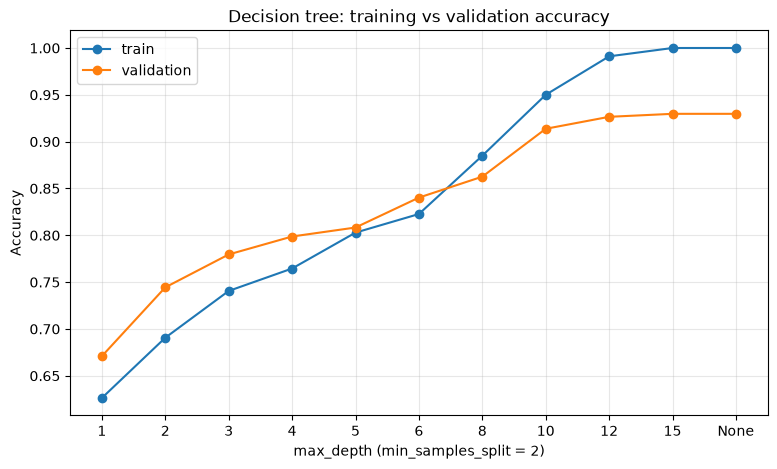

In [31]:
depth_values = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, None]
min_split_values = [2, 10, 20, 50]

dt_search = []
for depth, min_split in product(depth_values, min_split_values):
    tree = DecisionTreeClassifierScratch(max_depth=depth, min_samples_split=min_split).fit(Xc_train, yc_train)
    dt_search.append({"max_depth": depth, "min_samples_split": min_split, "n_nodes": tree.n_nodes_,
                      "train_accuracy": np.mean(tree.predict(Xc_train) == yc_train),
                      "val_accuracy": np.mean(tree.predict(Xc_val) == yc_val)})
dt_search = pd.DataFrame(dt_search)

# Best validation accuracy; among ties prefer the simplest tree (fewest nodes)
best_dt = dt_search.sort_values(["val_accuracy", "n_nodes"], ascending=[False, True]).iloc[0]
print(dt_search.sort_values(["val_accuracy", "n_nodes"], ascending=[False, True]).head(10).to_string(index=False))

curve = dt_search[dt_search.min_samples_split == 2].copy()
labels = ["None" if pd.isna(d) else str(int(d)) for d in curve.max_depth]
plt.plot(labels, curve.train_accuracy, "o-", label="train")
plt.plot(labels, curve.val_accuracy, "o-", label="validation")
plt.xlabel("max_depth (min_samples_split = 2)")
plt.ylabel("Accuracy")
plt.title("Decision tree: training vs validation accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [32]:
best_depth = None if pd.isna(best_dt.max_depth) else int(best_dt.max_depth)
best_min_split = int(best_dt.min_samples_split)
print(f"Best: max_depth={best_depth}, min_samples_split={best_min_split}")

dt = DecisionTreeClassifierScratch(max_depth=best_depth, min_samples_split=best_min_split).fit(Xc_train, yc_train)
classification_results["Decision Tree"] = classification_report(yc_test, dt.predict(Xc_test))

from sklearn.tree import DecisionTreeClassifier
sk_dt = DecisionTreeClassifier(criterion="entropy", max_depth=best_depth, min_samples_split=best_min_split,
                               random_state=RANDOM_STATE).fit(Xc_train, yc_train)
classification_results["Decision Tree (sklearn check)"] = classification_report(yc_test, sk_dt.predict(Xc_test))
print("Prediction agreement scratch vs sklearn:", np.mean(dt.predict(Xc_test) == sk_dt.predict(Xc_test)))
print("Root split feature:", X_cls_df.columns[dt.root_.feature])
pd.DataFrame(classification_results).T.round(4)

Best: max_depth=15, min_samples_split=10
Prediction agreement scratch vs sklearn: 1.0
Root split feature: family_history_with_overweight


,Accuracy,Precision,Recall,F1
Logistic Regression,0.7444,0.6868,0.8446,0.7576
Logistic Regression (sklearn check),0.7412,0.6851,0.8378,0.7538
KNN,0.9457,0.9338,0.9527,0.9431
KNN (sklearn check),0.9457,0.9338,0.9527,0.9431
Decision Tree,0.8978,0.8919,0.8919,0.8919
Decision Tree (sklearn check),0.8978,0.8919,0.8919,0.8919


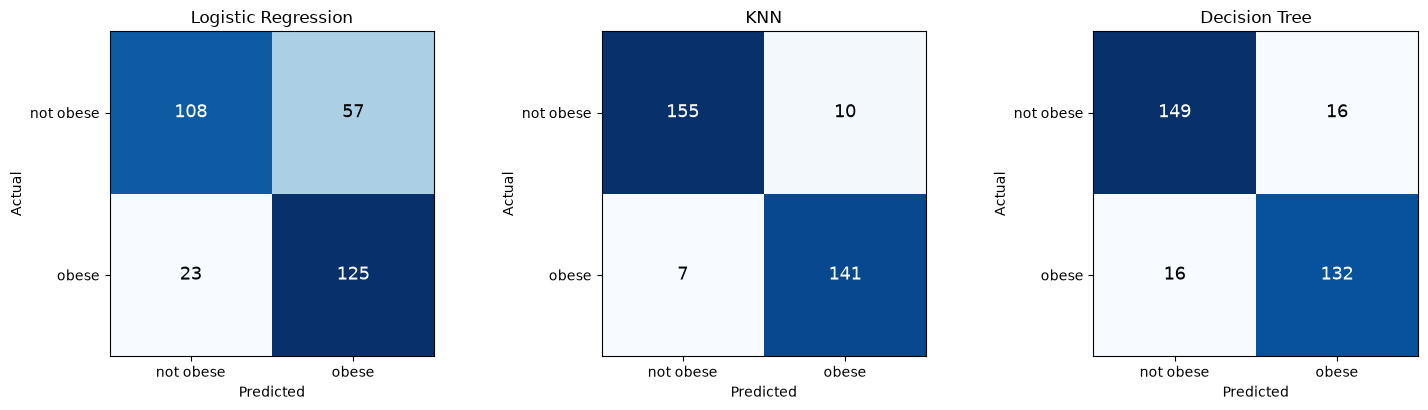

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, model) in zip(axes, [("Logistic Regression", log_reg), ("KNN", knn), ("Decision Tree", dt)]):
    cm = confusion_matrix(yc_test, model.predict(Xc_test))
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=13)
    ax.set_xticks([0, 1], ["not obese", "obese"])
    ax.set_yticks([0, 1], ["not obese", "obese"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 6. How much does target leakage inflate the results?

To show the effect discussed in Section 2 (and the reason why the original version of this notebook reported 100% accuracy),
the three classifiers are retrained with the same hyperparameters **adding `Weight` back** to the features, and the
linear regression is retrained **adding the one-hot encoded `NObeyesdad`** to its features.

In [34]:
X_leak_df = features.copy()  # includes Weight
Xl_train, Xl_val, Xl_test, *_ = split_and_scale(X_leak_df, y_cls)

leak_rows = []
for name, model in [
    ("Logistic Regression", LogisticRegressionGD(learning_rate=best_log.learning_rate,
                                                 n_iterations=int(best_log.n_iterations), l2=best_log.l2)),
    ("KNN", KNNClassifier(k=best_knn_k, metric=best_knn_metric)),
    ("Decision Tree", DecisionTreeClassifierScratch(max_depth=best_depth, min_samples_split=best_min_split)),
]:
    leaky_acc = np.mean(model.fit(Xl_train, yc_train).predict(Xl_test) == yc_test)
    leak_rows.append({"model": name, "metric": "accuracy",
                      "correct setup": classification_results[name]["Accuracy"], "with leaking feature": leaky_acc})

X_reg_leak_df = pd.concat([X_reg_df, pd.get_dummies(df["NObeyesdad"], dtype=int)], axis=1)
Xrl_train, _, Xrl_test, *_ = split_and_scale(X_reg_leak_df, y_reg)
leaky_lr = LinearRegressionClosedForm(l2=best_lambda).fit(Xrl_train, yr_train)
leak_rows.append({"model": "Linear Regression (closed form)", "metric": "RMSE [kg]",
                  "correct setup": regression_results["Linear Reg. (closed form)"]["RMSE"],
                  "with leaking feature": rmse(yr_test, leaky_lr.predict(Xrl_test))})

pd.DataFrame(leak_rows).set_index("model").round(4)

,metric,correct setup,with leaking feature
model,,,
Logistic Regression,accuracy,0.7444,0.9808
KNN,accuracy,0.9457,0.9712
Decision Tree,accuracy,0.8978,0.9936
Linear Regression (closed form),RMSE [kg],17.9688,5.3616


## 7. Final comparison (test set)

In [35]:
reg_table = pd.DataFrame(regression_results).T
cls_table = pd.DataFrame(classification_results).T
display(reg_table.round(3))
display(cls_table.round(4))

,MSE,RMSE,MAE,R2
Baseline (mean),628.768,25.075,20.698,-0.001
Linear Reg. (closed form),322.879,17.969,13.970,0.486
Linear Reg. (sklearn check),322.879,17.969,13.970,0.486
Linear Reg. (gradient descent),322.879,17.969,13.970,0.486
Neural Network,146.710,12.112,7.359,0.767
Neural Network (sklearn check),138.297,11.760,6.639,0.780


,Accuracy,Precision,Recall,F1
Logistic Regression,0.7444,0.6868,0.8446,0.7576
Logistic Regression (sklearn check),0.7412,0.6851,0.8378,0.7538
KNN,0.9457,0.9338,0.9527,0.9431
KNN (sklearn check),0.9457,0.9338,0.9527,0.9431
Decision Tree,0.8978,0.8919,0.8919,0.8919
Decision Tree (sklearn check),0.8978,0.8919,0.8919,0.8919


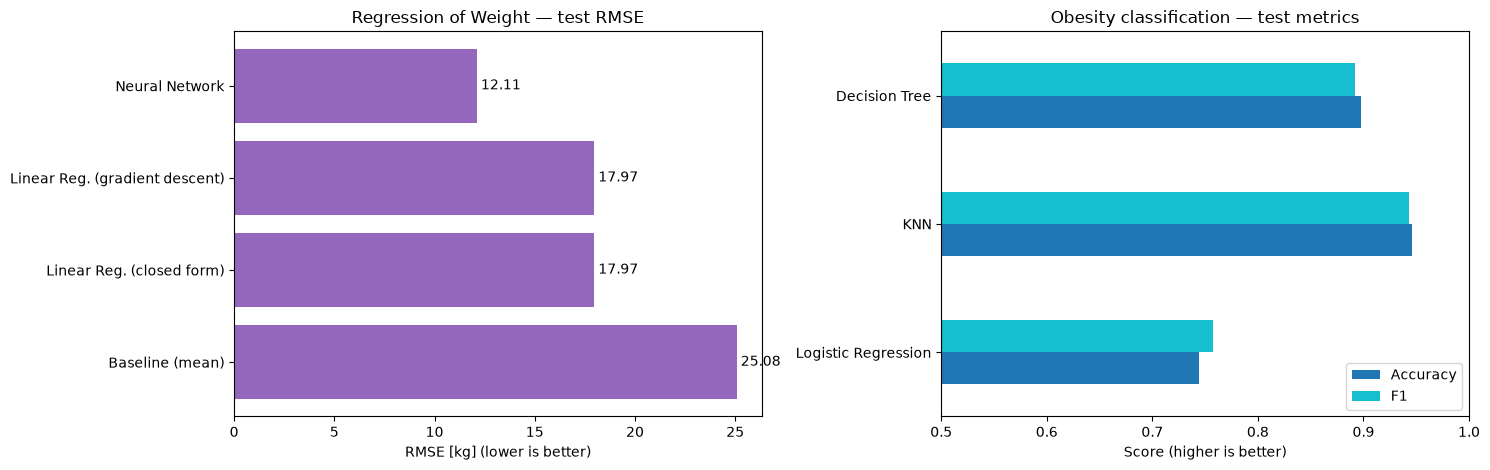

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
scratch_reg = reg_table.loc[[i for i in reg_table.index if "sklearn" not in i]]
axes[0].barh(scratch_reg.index, scratch_reg["RMSE"], color="tab:purple")
axes[0].set_xlabel("RMSE [kg] (lower is better)")
axes[0].set_title("Regression of Weight — test RMSE")
for i, v in enumerate(scratch_reg["RMSE"]):
    axes[0].text(v, i, f" {v:.2f}", va="center")

scratch_cls = cls_table.loc[[i for i in cls_table.index if "sklearn" not in i]]
scratch_cls[["Accuracy", "F1"]].plot.barh(ax=axes[1], color=["tab:blue", "tab:cyan"])
axes[1].set_xlim(0.5, 1.0)
axes[1].set_xlabel("Score (higher is better)")
axes[1].set_title("Obesity classification — test metrics")
plt.tight_layout()
plt.show()

## 8. Critical analysis

All numbers below refer to the test set of the fixed split used throughout the notebook (seed 42, 313 test samples).
With a test set of this size, one sample corresponds to about 0.3 accuracy points, and the standard error of an
accuracy around 90% is roughly ±1.7 points: differences of one or two points should not be over-interpreted.

### Methodology
- **Target leakage dominates everything else.** The obesity label is a function of `Weight / Height²`: a fixed rule
  `BMI >= 30` with no learning at all already reaches 99.7% accuracy. With `Weight` among the inputs every classifier scores
  97–99% (Section 6), which says nothing about the ability to predict obesity from lifestyle. The same holds for the
  regression: adding `NObeyesdad` to the inputs lowers the RMSE from about 18 kg to about 5 kg. Removing the leaking
  attribute is what turns the exercise into a meaningful prediction problem.
- **Train / validation / test.** Hyperparameters were always chosen on the validation set. Selecting them directly on the
  test set (as in the original version) produces optimistic estimates, because the test set ends up being part of the training
  process. The logistic regression is a good example: 83% accuracy on validation but 74% on test, and one would have
  reported the higher number had the test set been used to pick the model.
- **Pre-processing fitted on training data only.** Standardisation statistics come from the training set, so nothing about the
  validation/test distribution leaks into the models.
- **Synthetic data.** Most of the dataset (77%, according to its authors) was generated with SMOTE, which creates new points by
  interpolating between real neighbours of the same class. This favours local, neighbourhood-based methods and makes the
  results look better than they would on genuinely new people.

### Regression (`Weight`)
- **Linear regression** (closed form and gradient descent) reaches R² ≈ 0.49 and RMSE ≈ 18 kg, clearly better than the
  baseline (RMSE ≈ 25 kg) but far from precise: without the obesity class, weight depends on the lifestyle attributes in a
  strongly non-linear way.
- **Closed form vs gradient descent.** On standardised data gradient descent converges to the exact least-squares solution
  (parameters equal up to 4·10⁻⁴), confirming the correctness of both. Learning rate and number of iterations only affect
  *how fast* the minimum is reached: with η = 0.001 even 5000 iterations are not enough, with η ≥ 0.1 a few hundred suffice.
  The closed form needs no tuning and is the best choice at this scale (19 features); gradient descent becomes preferable
  when the number of features makes inverting XᵀX expensive, or when data do not fit in memory (mini-batch / stochastic
  variants).
- **Ridge penalty.** The validation MSE is flat for small λ and grows for large λ: with ~1500 samples and 19 features the
  unregularised model does not overfit, so λ = 0 is selected.
- **Neural network.** The MLP is the best regressor (R² ≈ 0.77, RMSE ≈ 12 kg, MAE ≈ 7 kg), confirming that the relationship
  is non-linear. Deeper (64-32) networks, the larger learning rate and more epochs performed best in the grid, and the
  scikit-learn MLP with the same architecture obtains a very similar error, which validates the from-scratch implementation
  (the analytical gradients also agree with the numerical ones to ~10⁻⁸). The best configuration is at the border of the grid
  (most epochs, largest learning rate), so extending the grid in that direction — ideally with early stopping on the
  validation loss — is the obvious next step. The price is a much higher training cost and many more hyperparameters
  than linear regression.

### Classification (obese vs. not obese)
- **KNN** is the best classifier (accuracy ≈ 94.6%, F1 ≈ 0.94) with k = 3 and Manhattan distance. Small k works best because
  of the SMOTE-generated data discussed above; accuracy decreases steadily as k grows. Its weaknesses are the prediction cost
  (distances to every training point for every query), the memory needed to keep the whole training set, and the dependence
  on feature scaling.
- **Decision tree** (accuracy ≈ 89.8%) captures non-linear interactions and is interpretable — the root split is on
  `family_history_with_overweight`. The tuning curve shows the classic bias–variance trade-off: shallow trees underfit, while
  an unrestricted tree reaches 100% training accuracy but loses validation accuracy. Pre-pruning with
  `min_samples_split = 10` gave the best validation score with a smaller tree. The from-scratch tree produces exactly the
  same predictions as scikit-learn's `DecisionTreeClassifier` with entropy criterion.
- **Logistic regression** is the weakest model (accuracy ≈ 74%, F1 ≈ 0.76): a single linear decision boundary is not enough
  for this problem. Its validation accuracy is almost identical for most hyperparameter combinations, a sign that the model is
  limited by its capacity, not by the optimisation. It remains the most interpretable: positive coefficients (e.g. family
  history, age, frequent snacking) increase the estimated probability of obesity, and it is cheap to train and to use.
  Feature engineering (interaction or polynomial terms) or a different decision threshold would be the way to improve it.

### Possible extensions
- k-fold cross-validation instead of a single validation split, to reduce the variance of the model selection.
- Random or Bayesian search for the neural network and wider grids where the optimum lies at the border.
- Ensembles of trees (random forest, gradient boosting) to reduce the variance of a single decision tree.
- Multi-class classification of all seven obesity levels.